## Snorkling Data Labelling
### By Ayush Varma (varma.ay@northeastern.edu)

In this lab, I will walk through the process of using Snorkel to build a training set for classifying YouTube comments as spam or not spam. The dataset contains comments from 5 of the most popular YouTube videos, originally introduced in the paper "TubeSpam: Comment Spam Filtering on YouTube" (T.C. Alberto, J.V. Lochter, J.V. Almeida).

The idea behind Snorkel is **weak supervision**. Instead of hand-labeling thousands of comments, we write **labeling functions (LFs)**, which are noisy, programmatic rules that assign labels to unlabeled data. Snorkel then combines these noisy votes into clean probabilistic labels using a `LabelModel`, and finally we train a real classifier on those labels.

#### Steps in this notebook:
1. **Loading Data**: Load the YouTube comments dataset and split it into train, dev, validation, and test sets
2. **Writing Labeling Functions**: Keyword LFs, regex LFs, factory-based LFs, VADER sentiment LFs, and a short-comment heuristic, checked against a labeled dev set
3. **Combining LF Outputs**: Compare the MajorityLabelVoter and Snorkel's LabelModel, and choose one on the validation set
4. **Training a Classifier**: Train four classifiers (Logistic Regression, Random Forest, SVM, and Naive Bayes) on the generated labels and compare them
5. **Evaluation and Data Slicing**: Confusion matrix, classification report, and per-slice scores for the best classifier
6. **Closing the Loop**: Use slices to find a blind spot, fix it with targeted transformation functions, and verify the fix on the same slices

In [1]:
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/bin/python3.12 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from snorkel.labeling import labeling_function

import os


# Turn off TensorFlow logging messages
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# For reproducibility
os.environ["PYTHONHASHSEED"] = "0"


In [3]:
DISPLAY_ALL_TEXT = False

pd.set_option("display.max_colwidth", 0 if DISPLAY_ALL_TEXT else 50)

In [4]:
df = pd.read_csv("data/Youtube01-Psy.csv")
df.head(10)

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1
5,LZQPQhLyRh9-wNRtlZDM90f1k0BrdVdJyN_YsaSwfxc,Jason Haddad,2013-11-26T02:55:11,"Hey, check out my new website!! This site is a...",1
6,z13lfzdo5vmdi1cm123te5uz2mqig1brz04,ferleck ferles,2013-11-27T21:39:24,Subscribe to my channel ﻿,1
7,z122wfnzgt30fhubn04cdn3xfx2mxzngsl40k,Bob Kanowski,2013-11-28T12:33:27,i turned it on mute as soon is i came on i jus...,0
8,z13ttt1jcraqexk2o234ghbgzxymz1zzi04,Cony,2013-11-28T16:01:47,You should check my channel for Funny VIDEOS!!﻿,1
9,z12avveb4xqiirsix04chxviiljryduwxg0,BeBe Burkey,2013-11-28T16:30:13,and u should.d check my channel and tell me wh...,1


In [5]:
from utils import load_spam_dataset

# split_dev_valid=True also returns two small labeled splits:
#   df_dev   : 100 labeled comments sampled from the training videos, used only to debug LFs
#   df_valid : 120 labeled comments from the held-out video, used to choose between models
# The 250-comment test set is identical to the one returned without split_dev_valid.
df_train, df_dev, df_valid, df_test = load_spam_dataset(split_dev_valid=True)

# We pull out the label vectors for ease of use later
Y_dev = df_dev.label.values
Y_valid = df_valid.label.values
Y_test = df_test.label.values

print(f"train={len(df_train)}  dev={len(df_dev)}  valid={len(df_valid)}  test={len(df_test)}")

train=1586  dev=100  valid=120  test=250


### Defining the constraints for spam filtering

In [6]:
# For clarity, defining constants to represent the class labels for spam, ham, and abstaining.
ABSTAIN = -1
HAM = 0
SPAM = 1

## 2. Writing Labeling Functions (LFs)
A gentle introduction to LFs
Labeling functions (LFs) help users encode domain knowledge and other supervision sources programmatically.

LFs are heuristics that take as input a data point and either assign a label to it (in this case, HAM or SPAM) or abstain (don't assign any label). Labeling functions can be noisy: they don't have perfect accuracy and don't have to label every data point. Moreover, different labeling functions can overlap (label the same data point) and even conflict (assign different labels to the same data point). This is expected, and we demonstrate how we deal with this later.

Because their only requirement is that they map a data point a label (or abstain), they can wrap a wide variety of forms of supervision. Examples include, but are not limited to:

Keyword searches: looking for specific words in a sentence
Pattern matching: looking for specific syntactical patterns
Third-party models: using an pre-trained model (usually a model for a different task than the one at hand)
Distant supervision: using external knowledge base
Crowdworker labels: treating each crowdworker as a black-box function that assigns labels to subsets of the data
Recommended practice for LF development

Note: I add an annotation called @labeling_function() for the snorkel to identify that this is a labeling function, without this, the function would still work as it is a plain function but snorkel would not know that this is a labeling function

#### Writing my own Labeling Functions

In [7]:
@labeling_function()
def lf_contains_subscribe_words(x):
    return SPAM if "subscribe" in x.text.lower() else ABSTAIN

@labeling_function()
def lf_contains_link(x):
    return SPAM if "http" in x.text.lower() else ABSTAIN

@labeling_function()
def lf_contains_check_out_words(x):
    return SPAM if "check out" in x.text.lower() else ABSTAIN


#### Checking out how my three LFs work on the training data

In [8]:
from snorkel.labeling import PandasLFApplier, LFAnalysis

#Adding the labeling functions to a list
labeling_function_list = [lf_contains_subscribe_words, lf_contains_link, lf_contains_check_out_words]

applier = PandasLFApplier(lfs=labeling_function_list)

L_train = applier.apply(df=df_train)

LFAnalysis(L=L_train, lfs=labeling_function_list).lf_summary()

  0%|          | 0/1586 [00:00<?, ?it/s]

100%|██████████| 1586/1586 [00:00<00:00, 113367.30it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
lf_contains_subscribe_words,0,[1],0.127364,0.020177,0.0
lf_contains_link,1,[1],0.119168,0.008197,0.0
lf_contains_check_out_words,2,[1],0.214376,0.023329,0.0


### Analysis of the labeling functions

The LF summary shows that `lf_contains_check_out_words` covers approximately 21% of the training data, while each of the other two labeling functions covers about 12%. Coverage is the proportion of training examples labeled by a function.

All three labeling functions have a positive polarity: they label examples as `SPAM`. None currently labels examples as `HAM`, because these functions are intended to identify spam. The conflict rate is zero, meaning that when multiple functions label the same example, they do not disagree. This does not mean that every function labels every example; some functions abstain.

Looking at `YouTube01-Psy.csv`, I noticed that some spam comments contain phrases such as “check” or “my channel,” which the current rules may not catch. The check-out rule requires the exact phrase “check out,” so it can miss comments containing only “check.” I plan to add labeling functions for these patterns to improve spam coverage.

In [9]:
#adding more labeling functions to the list
@labeling_function()
def lf_contains_my_channel(x):
    return SPAM if "my channel" in x.text.lower() else ABSTAIN

@labeling_function()
def lf_contains_sub_me(x):
    return SPAM if "sub me" in x.text.lower() else ABSTAIN

@labeling_function()
def lf_contains_follow_me(x):
    return SPAM if "follow me" in x.text.lower() else ABSTAIN

labeling_function_list = [lf_contains_subscribe_words, lf_contains_link, lf_contains_check_out_words, lf_contains_my_channel, lf_contains_sub_me, lf_contains_follow_me]

In [10]:
applier = PandasLFApplier(lfs=labeling_function_list)
L_train = applier.apply(df=df_train)

LFAnalysis(L=L_train, lfs=labeling_function_list).lf_summary()

  0%|          | 0/1586 [00:00<?, ?it/s]

100%|██████████| 1586/1586 [00:00<00:00, 68905.80it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
lf_contains_subscribe_words,0,[1],0.127364,0.049180,0.0
lf_contains_link,1,[1],0.119168,0.008827,0.0
lf_contains_check_out_words,2,[1],0.214376,0.039723,0.0
lf_contains_my_channel,3,[1],0.069987,0.051072,0.0
lf_contains_sub_me,4,[1],0.001261,0.000631,0.0
lf_contains_follow_me,5,[1],0.007566,0.003153,0.0


### Updating the labeling functions

The new `lf_contains_sub_me` and `lf_contains_follow_me` labeling functions have very low coverage: about 0.1% and 0.8% of the training data, respectively. They match very few comments, so I'll drop them from the labeling function set for now.

Next, I'll write labeling functions that identify likely genuine comments as `HAM`. These will let me examine cases where a HAM rule and a SPAM rule label the same comment differently, creating conflicts.

In [11]:
def get_labeling_function_summary(labeling_functions_list, dataframe):
    applier = PandasLFApplier(lfs=labeling_functions_list)

    labeling_matrix = applier.apply(df= dataframe)

    return LFAnalysis(L= labeling_matrix, lfs = labeling_functions_list).lf_summary()

In [12]:
#writing some HAM LFs

@labeling_function()
def lf_contains_song(x):
    return HAM if "song" in x.text.lower() else ABSTAIN

@labeling_function()
def lf_short_comment(x):
    return HAM if len(x.text.split()) < 10 else ABSTAIN


labeling_function_list.extend([lf_contains_song, lf_short_comment])

get_labeling_function_summary(labeling_function_list, df_train)


  0%|          | 0/1586 [00:00<?, ?it/s]

100%|██████████| 1586/1586 [00:00<00:00, 54580.53it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
lf_contains_subscribe_words,0,[1],0.127364,0.085750,0.051702
lf_contains_link,1,[1],0.119168,0.083859,0.076293
lf_contains_check_out_words,2,[1],0.214376,0.160782,0.134300
lf_contains_my_channel,3,[1],0.069987,0.061791,0.032787
lf_contains_sub_me,4,[1],0.001261,0.001261,0.000631
lf_contains_follow_me,5,[1],0.007566,0.006305,0.005044
lf_contains_song,6,[0],0.141866,0.090164,0.032156
lf_short_comment,7,[0],0.573140,0.303909,0.245902


##### Adding a function which can create new lfs without having to write it manually again and again

##### How the factory function works

- `keyword_lookup(x, keywords, label)`: the **logic**. It checks if any keyword from the list exists in the comment. If yes, returns the label (SPAM or HAM). If no match, returns ABSTAIN.
- `make_keyword_lf(keywords, label)`: the **wrapper**. It takes the logic function and wraps it into a Snorkel `LabelingFunction` object so Snorkel can track it. It uses `resources` to pass the keyword list and label into `keyword_lookup`.
- **Why?** Instead of writing 10 separate `@labeling_function()` decorated functions that all do the same keyword check, we write one template and reuse it.

**Note:** Using very long/specific phrases like `"please check out my channel"` reduces coverage. Shorter keywords like `"please"` catch more comments. Snorkel's LabelModel handles the noise.

In [13]:
# I am now creating a factory function to create labeling functions for a given list of keywords. This will help us create labeling functions for both SPAM and HAM classes without having to without having to write the same repetitive code for each keyword.
from snorkel.labeling import LabelingFunction

def keyword_lookup(x, keywords, label):
    if any(word in x.text.lower() for word in keywords):
        return label
    else:
        return ABSTAIN

    
def make_keyword_lf(keywords, label):
    return LabelingFunction(
        name = f"keyword_{keywords[0]}",
        f= keyword_lookup,
        resources = dict(keywords=keywords, label=label),
    )



In [14]:

#SPAM LFs
keyword_please = make_keyword_lf(["please subscribe", "please check out", "please follow me", "please sub me", "please check out my channel", "plz", "pls"], SPAM)
keyword_subscribe = make_keyword_lf(["subscribe"], SPAM)
keyword_free = make_keyword_lf(["free", "win", ], SPAM)
keyword_check = make_keyword_lf(["check out", "check me"], SPAM)


# HAM LFs

keyword_song = make_keyword_lf(["song", "music", "beat"], HAM)
keyword_love = make_keyword_lf(["love", "like", "loved"], label= HAM)
keyword_funny = make_keyword_lf(["funny", "lol", "hahaha"], label= HAM)


labeling_function_list = [keyword_please, keyword_subscribe, keyword_free, keyword_check, keyword_song, keyword_love, keyword_funny]
get_labeling_function_summary(labeling_function_list, df_train)

  0%|          | 0/1586 [00:00<?, ?it/s]

100%|██████████| 1586/1586 [00:00<00:00, 23915.75it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
keyword_please subscribe,0,[1],0.044136,0.038462,0.022699
keyword_subscribe,1,[1],0.127364,0.066204,0.051702
keyword_free,2,[1],0.035939,0.022699,0.018916
keyword_check out,3,[1],0.216267,0.068726,0.060530
keyword_song,4,[0],0.195460,0.110971,0.056116
keyword_love,5,[0],0.216267,0.122951,0.068096
keyword_funny,6,[0],0.029634,0.015132,0.007566


### Analysis of the factory-based labeling functions

Using the factory function, I created 4 SPAM labeling functions (`keyword_please subscribe`, `keyword_subscribe`, `keyword_free`, `keyword_check out`) and 3 HAM labeling functions (`keyword_song`, `keyword_love`, `keyword_funny`). We can now see both `[0]` (HAM) and `[1]` (SPAM) in the Polarity column, which means Snorkel is hearing both sides.

`keyword_check out` and `keyword_love` have the highest coverage at ~21.6% each. `keyword_funny` has the lowest at ~2.9%, not many people write "lol" or "hahaha" in YouTube comments. Conflicts are now appearing (e.g. `keyword_check out` at 6%), meaning some comments are being labeled SPAM by one LF and HAM by another, this is expected and Snorkel's LabelModel will resolve these disagreements.

So, from now onwards, we have been using the factory function to create the labeling functions and I have created 4 SPAM labeling functions, which have different keywords and 3 HAM labeling functions which have multiple different keywords. Now I will move on to regex matching labeling functions, and then move towards the TextBlob and a few NLP labeling functions. After that I would combine all of these votes into a probabilistic labeling and finally train a classifier.

### 3. Regex-based Labeling Functions
Regex LFs give us more flexibility than exact keyword matching. Instead of checking for the exact phrase "check out", we can use check.*out to catch variations like "check me out", "check it out", "check this out", etc. I'm also adding regex patterns for URLs and comments with excessive ALL CAPS words.

Using `re.I` to search case-insensitive 

In [15]:
import re

@labeling_function()
def lf_regex_check_out(x):
    """Catches 'check out', 'check my page out', 'check my channel out' etc."""
    return SPAM if re.search(r"check.*out", x.text, flags=re.I) else ABSTAIN

@labeling_function()
def lf_regex_url(x):
    """Catches any URL in the comment"""
    return SPAM if re.search(r"https?://|www\.|\.com|\.ly|\.net|\.org", x.text, flags=re.I) else ABSTAIN

@labeling_function()
def lf_regex_subscribe(x):
    """Catches 'subscribe', 'sub me', 'sub to my channel' etc."""
    return SPAM if re.search(r"sub.*(me|to|my channel)", x.text, flags=re.I) else ABSTAIN


labeling_function_list.extend([lf_regex_check_out, lf_regex_url, lf_regex_subscribe])
get_labeling_function_summary(labeling_function_list, df_train)

  0%|          | 0/1586 [00:00<?, ?it/s]

100%|██████████| 1586/1586 [00:00<00:00, 20092.75it/s]

/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
keyword_please subscribe,0,[1],0.044136,0.042245,0.022699
keyword_subscribe,1,[1],0.127364,0.107188,0.051702
keyword_free,2,[1],0.035939,0.033417,0.018916
keyword_check out,3,[1],0.216267,0.216267,0.060530
keyword_song,4,[0],0.195460,0.116646,0.064943
keyword_love,5,[0],0.216267,0.134931,0.083228
keyword_funny,6,[0],0.029634,0.017024,0.009458
lf_regex_check_out,7,[1],0.233922,0.228878,0.067465
lf_regex_url,8,[1],0.142497,0.065574,0.030265
lf_regex_subscribe,9,[1],0.091425,0.087011,0.034678


### Analysis of the regex-based labeling functions

After adding the regex LFs, I can see that `lf_regex_check_out` (23.3% coverage) works better than the keyword `keyword_check out` (21.6% coverage). That's an additional ~2% of the training data that the exact keyword rule was missing, these are comments where "check" and "out" appear in the text but not right next to each other, like "check me out", "check it out", or "check my channel out". The keyword rule only catches the exact phrase "check out", so it misses all these variations.

Similarly, `lf_regex_url` catches 14.2% of the data compared to the earlier `lf_contains_link` which only looked for "http". The regex also picks up ".com", ".ly", ".net" patterns, catching links that don't start with "http" but are still URLs. And `lf_regex_subscribe` at 9.1% catches cases like "sub to my channel" or "sub me" that the plain "subscribe" keyword would miss.

The overlaps are now much higher (e.g. `keyword_check out` at 21.6% overlap) because the regex and keyword rules are labeling many of the same comments, which makes sense since the regex is a superset of the keyword rule. Conflicts have also gone up slightly because more LFs are now voting, increasing the chance of a SPAM LF and a HAM LF disagreeing on the same comment.

### 4. Sentiment-based Labeling Functions (VADER)
Instead of TextBlob (used in the original tutorial), I'm using VADER (Valence Aware Dictionary for Sentiment Reasoning) from NLTK. VADER is specifically tuned for social media text like YouTube comments. It gives a compound score from -1 (most negative) to +1 (most positive). Very positive comments are likely genuine reactions (HAM), while very negative scores might indicate aggressive spam.

Note: I use compound scores since they give me an overall score combining all the three (positive, negative, neutral) scores

In [16]:
!pip install nltk -q

zsh:1: command not found: pip


In [17]:
import nltk
nltk.download('vader_lexicon')

from nltk.sentiment.vader import SentimentIntensityAnalyzer

sid = SentimentIntensityAnalyzer()

@labeling_function()
def lf_vader_positive_sentiment_analyzer(x):
    """Catches very positive comments that are usually geniune HAM, using compound score"""
    score = sid.polarity_scores(x.text)["compound"]
    return HAM if score > 0.8 else ABSTAIN
    


@labeling_function()
def lf_vader_negative_sentiment_analyzer(x):
    """Catches very negative comments that are usually SPAM, using compound score"""
    score = sid.polarity_scores(x.text)["compound"]
    return SPAM if score < -0.5 else ABSTAIN


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/ayush/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [18]:
labeling_function_list.extend([lf_vader_positive_sentiment_analyzer, lf_vader_negative_sentiment_analyzer])
get_labeling_function_summary(labeling_function_list, df_train)


  0%|          | 0/1586 [00:00<?, ?it/s]

 38%|███▊      | 604/1586 [00:00<00:00, 6036.45it/s]

 83%|████████▎ | 1311/1586 [00:00<00:00, 6641.43it/s]

100%|██████████| 1586/1586 [00:00<00:00, 6256.41it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
keyword_please subscribe,0,[1],0.044136,0.042245,0.024590
keyword_subscribe,1,[1],0.127364,0.109710,0.056116
keyword_free,2,[1],0.035939,0.034048,0.022699
keyword_check out,3,[1],0.216267,0.216267,0.066204
keyword_song,4,[0],0.195460,0.133039,0.079445
keyword_love,5,[0],0.216267,0.148802,0.087642
keyword_funny,6,[0],0.029634,0.018285,0.010088
lf_regex_check_out,7,[1],0.233922,0.229508,0.075032
lf_regex_url,8,[1],0.142497,0.070618,0.038462
lf_regex_subscribe,9,[1],0.091425,0.087011,0.037201


### Analysis of the VADER sentiment labeling functions

The positive VADER LF (compound > 0.8, votes HAM) covers about 10.5% of the training data, and the negative one (compound < -0.5, votes SPAM) covers about 4.2%. Most spam is promotional ("check out my channel!"), which VADER scores as neutral or positive rather than negative, so the negative threshold catches little.

The positive LF conflicts with other LFs on 6.7% of the training data, more than most keyword rules. Comments like "Amazing song! please subscribe to my channel" are very positive in tone but are clearly spam. Coverage and conflicts alone cannot tell me whether these LFs are right, so the next step checks them against labeled data.

### Checking LF accuracy on the dev set

Coverage, overlaps, and conflicts tell me how often an LF votes, but not whether its votes are right. The 100-comment dev set has real labels, so passing `Y=Y_dev` to `lf_summary()` adds `Correct`, `Incorrect`, and `Emp. Acc.` columns. I only use the dev set for this kind of debugging, never for the final score.

In [19]:
L_dev = PandasLFApplier(lfs=labeling_function_list).apply(df=df_dev)
LFAnalysis(L=L_dev, lfs=labeling_function_list).lf_summary(Y=Y_dev)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:00<00:00, 5482.18it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts,Correct,Incorrect,Emp. Acc.
keyword_please subscribe,0,[1],0.04,0.04,0.02,4,0,1.000000
keyword_subscribe,1,[1],0.14,0.11,0.03,14,0,1.000000
keyword_free,2,[1],0.04,0.04,0.01,4,0,1.000000
keyword_check out,3,[1],0.23,0.23,0.12,23,0,1.000000
keyword_song,4,[0],0.24,0.18,0.14,15,9,0.625000
keyword_love,5,[0],0.12,0.09,0.05,6,6,0.500000
keyword_funny,6,[0],0.04,0.01,0.01,2,2,0.500000
lf_regex_check_out,7,[1],0.29,0.27,0.14,29,0,1.000000
lf_regex_url,8,[1],0.14,0.10,0.06,14,0,1.000000
lf_regex_subscribe,9,[1],0.10,0.10,0.02,10,0,1.000000


### What the dev set revealed

The keyword and regex SPAM rules are 100% accurate on the dev set, but both VADER LFs point in the **wrong direction**:
- `lf_vader_positive_sentiment_analyzer` (very positive means HAM) is right on only 2 of 11 comments (18%). Very positive comments are mostly spam: spammers write upbeat, excited messages to get clicks.
- `lf_vader_negative_sentiment_analyzer` (very negative means SPAM) is right on 0 of 6 comments. Very negative comments come from real viewers who dislike the video or argue in the comments.

So the sentiment signal is useful, just inverted. The cell below flips both rules and also adds a short-comment HAM rule (fewer than 5 words, as in the original tutorial). On the dev set the flipped rules are 82% and 100% accurate, and the short-comment rule is 68% accurate.

In [20]:
@labeling_function()
def lf_vader_positive_spam(x):
    """Very positive comments are usually promotional spam ('Amazing song! check out my channel')"""
    score = sid.polarity_scores(x.text)["compound"]
    return SPAM if score > 0.8 else ABSTAIN


@labeling_function()
def lf_vader_negative_ham(x):
    """Very negative comments are usually real viewers reacting to the video"""
    score = sid.polarity_scores(x.text)["compound"]
    return HAM if score < -0.5 else ABSTAIN


@labeling_function()
def lf_short_comment_5(x):
    """Very short comments ('nice video', 'love this') are usually HAM"""
    return HAM if len(x.text.split()) < 5 else ABSTAIN


new_lfs = [lf_vader_positive_spam, lf_vader_negative_ham, lf_short_comment_5]
L_dev_new = PandasLFApplier(lfs=new_lfs).apply(df=df_dev)
LFAnalysis(L=L_dev_new, lfs=new_lfs).lf_summary(Y=Y_dev)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:00<00:00, 7398.01it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts,Correct,Incorrect,Emp. Acc.
lf_vader_positive_spam,0,[1],0.11,0.0,0.0,9,2,0.818182
lf_vader_negative_ham,1,[0],0.06,0.0,0.0,6,0,1.000000
lf_short_comment_5,2,[0],0.28,0.0,0.0,19,9,0.678571


### Cleaning up the labeling function set before training

Based on the training summaries and the dev set check, I made these changes:
- **Dropped `keyword_love`**: it includes "like", which is too common a word and adds noise.
- **Dropped the duplicate keyword rules** `keyword_check out` and `keyword_subscribe`: `lf_regex_check_out` and `lf_regex_subscribe` already cover the same comments. The LabelModel assumes LFs are conditionally independent, so near-copies make it count the same signal twice.
- **Replaced both VADER LFs with their flipped versions** (`lf_vader_positive_spam`, `lf_vader_negative_ham`), because the dev set showed the original direction was wrong.
- **Added `lf_short_comment_5`** (fewer than 5 words). My earlier 10-word version covered 57% of the data and was too broad; the 5-word version is the HAM rule the original tutorial relies on, and without it most HAM comments get no vote at all.

In [21]:
labeling_function_list = [
    # SPAM
    keyword_please,
    keyword_free,
    lf_regex_check_out,
    lf_regex_url,
    lf_regex_subscribe,
    lf_vader_positive_spam,
    # HAM
    keyword_song,
    keyword_funny,
    lf_vader_negative_ham,
    lf_short_comment_5,
]

get_labeling_function_summary(labeling_function_list, df_train)

  0%|          | 0/1586 [00:00<?, ?it/s]

 41%|████      | 652/1586 [00:00<00:00, 6519.66it/s]

 87%|████████▋ | 1381/1586 [00:00<00:00, 6971.69it/s]

100%|██████████| 1586/1586 [00:00<00:00, 6598.73it/s]


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/snorkel/labeling/analysis.py:61: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  m = sparse.diags(np.ravel(self._L_sparse.max(axis=1).todense()))


,j,Polarity,Coverage,Overlaps,Conflicts
keyword_please subscribe,0,[1],0.044136,0.041614,0.015763
keyword_free,1,[1],0.035939,0.034048,0.011349
lf_regex_check_out,2,[1],0.233922,0.097730,0.052333
lf_regex_url,3,[1],0.142497,0.104035,0.060530
lf_regex_subscribe,4,[1],0.091425,0.054224,0.028373
lf_vader_positive_spam,5,[1],0.105296,0.083228,0.039092
keyword_song,6,[0],0.195460,0.123581,0.076923
keyword_funny,7,[0],0.029634,0.017654,0.012610
lf_vader_negative_ham,8,[0],0.041614,0.022699,0.004414
lf_short_comment_5,9,[0],0.225725,0.097730,0.063682


In [22]:
applier = PandasLFApplier(lfs=labeling_function_list)
L_train = applier.apply(df=df_train)
L_valid = applier.apply(df=df_valid)
L_test = applier.apply(df=df_test)

print(f"Train comments with at least one LF vote: {100 * (L_train != ABSTAIN).any(axis=1).mean():.1f}%")

  0%|          | 0/1586 [00:00<?, ?it/s]

 41%|████      | 652/1586 [00:00<00:00, 6516.17it/s]

 87%|████████▋ | 1378/1586 [00:00<00:00, 6947.44it/s]

100%|██████████| 1586/1586 [00:00<00:00, 6593.36it/s]

  0%|          | 0/120 [00:00<?, ?it/s]

100%|██████████| 120/120 [00:00<00:00, 6023.13it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

100%|██████████| 250/250 [00:00<00:00, 5599.72it/s]

Train comments with at least one LF vote: 76.2%


### 5. Combining Labeling Function Outputs with the LabelModel
Now that we have keyword LFs, regex LFs, sentiment LFs, and heuristic LFs, we combine all their votes. First we apply all LFs to the train, validation, and test sets to get the label matrices, then we use two models to combine the noisy votes:

1. **MajorityLabelVoter**: a simple baseline that counts votes and picks the majority. Every LF gets equal weight. Ties and comments with no votes are broken with `tie_break_policy="random"`. This is the simple approach to compare against.

2. **LabelModel**: Snorkel's model that **learns which LFs are more accurate** by analyzing how they agree and disagree with each other. It gives higher weight to better LFs and produces **probabilistic labels** (e.g. 0.85 probability SPAM) for each data point. No gold labels are needed for training; it only uses the label matrix `L_train`.

Note: `cardinality=2` means we have 2 classes (HAM and SPAM). ABSTAIN (-1) is not a class; it just means an LF has no opinion on that data point, and the LabelModel skips those votes when combining.

In [23]:
from snorkel.labeling.model import LabelModel, MajorityLabelVoter

# Majority Vote baseline: every LF gets the same weight
majority_model = MajorityLabelVoter()

# Snorkel LabelModel: learns a weight per LF from L_train only (no gold labels)
label_model = LabelModel(cardinality=2, verbose=True)
label_model.fit(L_train=L_train, n_epochs=500, log_freq=100, seed=123)

# tie_break_policy="random" picks a label for tied or fully-abstained comments using a deterministic hash
def score(model, L, Y):
    return model.score(L=L, Y=Y, tie_break_policy="random")["accuracy"]

majority_valid, label_model_valid = score(majority_model, L_valid, Y_valid), score(label_model, L_valid, Y_valid)
majority_accuracy, label_model_accuracy = score(majority_model, L_test, Y_test), score(label_model, L_test, Y_test)

print(f"{'':<14}{'Valid':>8}{'Test':>8}")
print(f"{'MajorityVoter':<14}{100*majority_valid:>7.1f}%{100*majority_accuracy:>7.1f}%")
print(f"{'LabelModel':<14}{100*label_model_valid:>7.1f}%{100*label_model_accuracy:>7.1f}%")

INFO:root:Computing O...


INFO:root:Estimating \mu...


  0%|          | 0/500 [00:00<?, ?epoch/s]

INFO:root:[0 epochs]: TRAIN:[loss=0.067]


INFO:root:[100 epochs]: TRAIN:[loss=0.006]


INFO:root:[200 epochs]: TRAIN:[loss=0.003]


INFO:root:[300 epochs]: TRAIN:[loss=0.003]


INFO:root:[400 epochs]: TRAIN:[loss=0.003]


100%|██████████| 500/500 [00:00<00:00, 7311.33epoch/s]


INFO:root:Finished Training


                 Valid    Test
MajorityVoter    85.8%   85.2%
LabelModel       72.5%   74.4%


### Analysis of the LabelModel vs MajorityVoter

After the cleanup, majority vote scores 85.8% on validation and 85.2% on test, above the original tutorial's 83.6%. Before the cleanup, the same model scored 71.6% on test: the inverted VADER rules pushed comments toward the wrong label, and with too few HAM rules about 38% of test comments had no vote at all and got a random label.

The LabelModel improved too (54.8% to 74.4% on test), but it still trails majority vote. My guess is that my LF set breaks the LabelModel's assumption that LFs make independent errors: several SPAM rules fire on the same promotional comments (for example "check out my channel http://..." triggers the check-out regex, the URL regex, and often the positive VADER rule), so the model cannot tell an accurate LF from one that just agrees with its neighbors. With only 10 LFs there is not much other signal to correct for this.

I make the choice between the two on the **validation** set, not the test set, so the test set is only used for the final scores below.

In [24]:
from snorkel.labeling import filter_unlabeled_dataframe
from snorkel.utils import probs_to_preds

# Step 1: Pick the label source using the VALIDATION set, so the test set stays untouched until the end
label_source_name, label_source = (
    ("MajorityVoter", majority_model) if majority_valid >= label_model_valid else ("LabelModel", label_model)
)
print(f"Training labels come from: {label_source_name}")
probs_train = label_source.predict_proba(L=L_train)

# Step 2: Filter out data points where no LF voted
df_train_filtered, probs_train_filtered = filter_unlabeled_dataframe(X=df_train, y=probs_train, L=L_train)

# Step 3: Convert probabilities to hard labels (sklearn needs 0 or 1, not 0.73)
preds_train_filtered = probs_to_preds(probs=probs_train_filtered)
print(f"Training comments kept: {len(df_train_filtered)} of {len(df_train)}")

Training labels come from: MajorityVoter
Training comments kept: 1209 of 1586


In [25]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(ngram_range=(1, 5))
X_train = vectorizer.fit_transform(df_train_filtered.text.tolist())
X_test = vectorizer.transform(df_test.text.tolist())

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Logistic Regression": LogisticRegression(C=1e3, solver="liblinear"),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=123),
    "SVM": LinearSVC(C=1e3, max_iter=5000),
    "Naive Bayes": MultinomialNB(),
}

results = {}
for name, model in models.items():
    model.fit(X=X_train, y=preds_train_filtered)
    acc = model.score(X=X_test, y=Y_test)
    results[name] = acc
    print(f"{name:<25} {acc * 100:.1f}%")


Logistic Regression       90.0%


Random Forest             85.6%


SVM                       87.2%
Naive Bayes               86.8%


/Users/ayush/Downloads/Fall2026/IE7374-MLOPS/lab_04/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


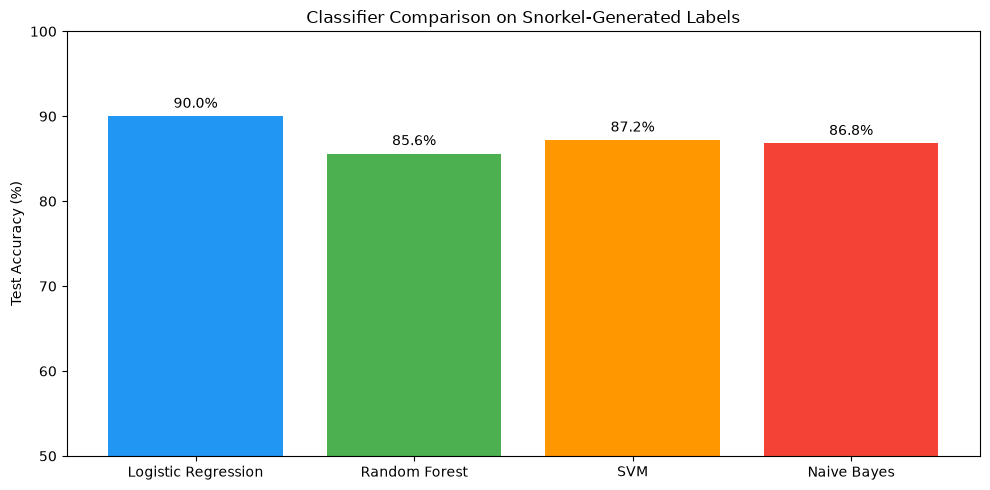

In [27]:
import matplotlib.pyplot as plt

names = list(results.keys())
accuracies = [v * 100 for v in results.values()]

plt.figure(figsize=(10, 5))
bars = plt.bar(names, accuracies, color=["#2196F3", "#4CAF50", "#FF9800", "#F44336"])
plt.ylabel("Test Accuracy (%)")
plt.title("Classifier Comparison on Snorkel-Generated Labels")
plt.ylim(50, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{acc:.1f}%", ha="center")

plt.tight_layout()
plt.show()


### Reflections and Observations

**Snorkel is not just about automating labeling.** Each labeling function is a small rule-based labeler, and the `@labeling_function()` decorator makes it simple to run these rules over all the data. The hard part is deciding how much to trust each rule and how to merge their votes into one label.

**Coverage statistics are not enough.** My first pass judged LFs only by coverage, overlaps, and conflicts, and two of them (the VADER rules) were confidently wrong. A 100-comment labeled dev set and `lf_summary(Y=Y_dev)` exposed this immediately. Flipping them, removing duplicate rules, and adding a short-comment HAM rule raised majority-vote accuracy from 71.6% to 85.2% on test.

**MajorityLabelVoter vs LabelModel:**
1. The **MajorityLabelVoter** gives every LF the same weight. Simple and transparent.
2. The **LabelModel** learns a weight per LF from how they agree and disagree, without gold labels.

For my LF set, the LabelModel stayed below majority vote (72.5% vs 85.8% on validation), so the notebook picks the MajorityVoter labels. The choice is made on validation so the test set stays clean.

**Training the four classifiers:** All four classifiers train on the same 1,209 labeled comments with TF-IDF features. Logistic Regression is best at 90.0%, almost 5 points above the labels it learned from, because it picks up on text patterns that no single LF encodes.

**Garbage in, garbage out:** With my first LF set, the training labels were 71.6% accurate and the best classifier reached 82.0%. Fixing the labels raised the best classifier to 90.0% without changing anything about the classifiers themselves.

**Future work:** Use the trained classifier to flag new YouTube comments as they arrive, and add slice monitoring to that service so a new blind spot shows up as a slice score drop instead of as complaints. The slicing and augmentation loop is in section 8.

### LF Coverage Distribution
This histogram shows how many labeling functions voted on each data point. Data points with 0 LF labels get filtered out before training. Ideally, we want most data points to have at least 2-3 LF votes for the MajorityVoter to make reliable decisions.

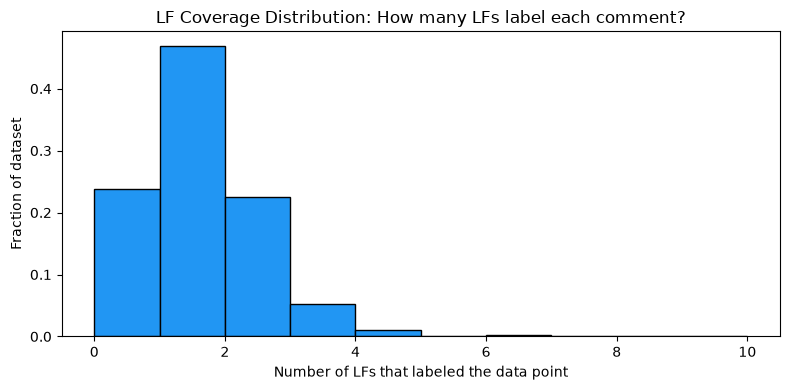

In [28]:
def plot_label_frequency(L):
    plt.figure(figsize=(8, 4))
    plt.hist((L != -1).sum(axis=1), density=True, bins=range(L.shape[1] + 1), edgecolor="black", color="#2196F3")
    plt.xlabel("Number of LFs that labeled the data point")
    plt.ylabel("Fraction of dataset")
    plt.title("LF Coverage Distribution: How many LFs label each comment?")
    plt.tight_layout()
    plt.show()

plot_label_frequency(L_train)

### Confusion Matrix and Classification Report
Let's look at the best classifier in more detail. The confusion matrix shows where the model gets confused: how many HAM comments it misclassifies as SPAM and vice versa. The classification report gives us precision, recall, and F1-score per class.

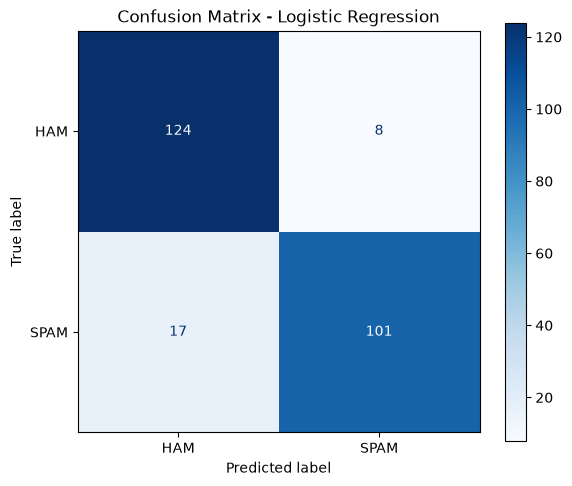

              precision    recall  f1-score   support

         HAM       0.88      0.94      0.91       132
        SPAM       0.93      0.86      0.89       118

    accuracy                           0.90       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250



In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Best classifier from the comparison above (already fitted)
best_name = max(results, key=results.get)
best_model = models[best_name]
y_pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(Y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["HAM", "SPAM"])
disp.plot(ax=ax, cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

print(classification_report(Y_test, y_pred, target_names=["HAM", "SPAM"]))

### Full Model Comparison (including LabelModel and MajorityVoter)
Let's compare all 6 models side by side: the two Snorkel models (LabelModel and MajorityVoter) and the four sklearn classifiers. This shows how each step of the pipeline improves on the last.

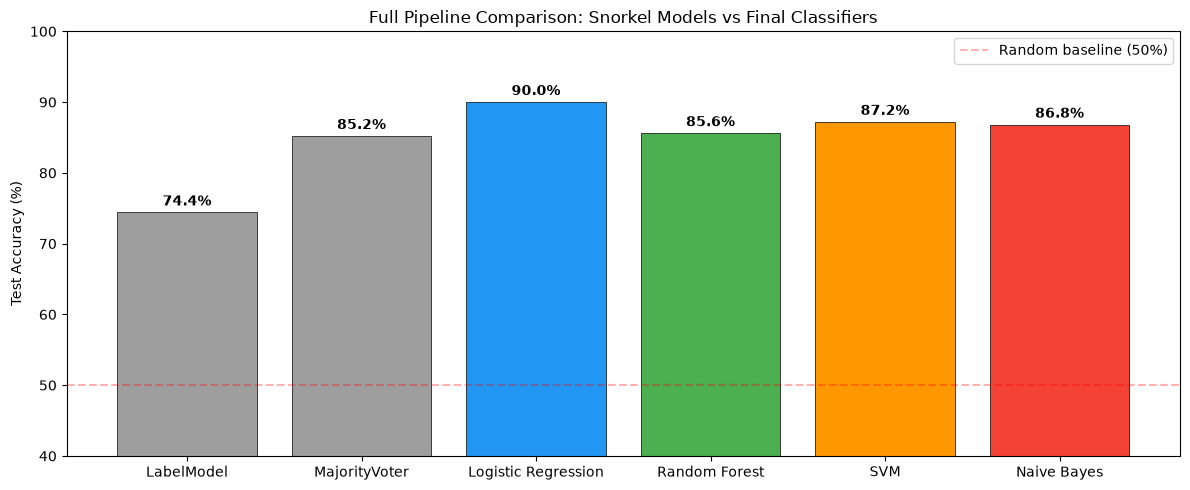

In [30]:
# Full comparison: Snorkel models + sklearn classifiers
all_results = {
    "LabelModel": label_model_accuracy,
    "MajorityVoter": majority_accuracy,
    **results,
}

names = list(all_results.keys())
accuracies = [v * 100 for v in all_results.values()]
colors = ["#9E9E9E", "#9E9E9E", "#2196F3", "#4CAF50", "#FF9800", "#F44336"]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(names, accuracies, color=colors, edgecolor="black", linewidth=0.5)

ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Full Pipeline Comparison: Snorkel Models vs Final Classifiers")
ax.set_ylim(40, 100)
ax.axhline(y=50, color="red", linestyle="--", alpha=0.3, label="Random baseline (50%)")

for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{acc:.1f}%", ha="center", fontweight="bold")

ax.legend()
plt.tight_layout()
plt.show()

## 7. Data Slicing: Monitoring Performance on Critical Subsets

In real-world applications, overall accuracy can hide poor performance on important subsets of data. For example, our model might do great overall but fail on short comments or comments with links. Slicing functions (SFs) let us define these critical subsets and monitor per-slice performance.

This is inspired by the original `03_spam_data_slicing_tutorial`. Instead of just looking at one accuracy number, we check how the best classifier performs on specific types of comments.

In [31]:
from snorkel.slicing import slicing_function, PandasSFApplier
from snorkel.analysis import Scorer
from snorkel.utils import preds_to_probs

@slicing_function()
def short_comment(x):
    """Short comments (< 5 words) like 'cool!' or 'nice video'"""
    return len(x.text.split()) < 5

@slicing_function()
def has_link(x):
    """Comments containing URLs"""
    return bool(re.search(r"https?://|www\.|\.com|\.ly", x.text, flags=re.I))

@slicing_function()
def has_emoji_or_punctuation(x):
    """Comments with excessive punctuation or emoji-like characters"""
    return x.text.count("!") >= 2 or x.text.count(":") >= 2

sfs = [short_comment, has_link, has_emoji_or_punctuation]

# Apply slicing functions to test set
sf_applier = PandasSFApplier(sfs)
S_test = sf_applier.apply(df_test)

# Score per slice
scorer = Scorer(metrics=["f1", "accuracy"])
probs_test = preds_to_probs(y_pred, 2)

slice_scores = scorer.score_slices(
    S=S_test, golds=Y_test, preds=y_pred, probs=probs_test, as_dataframe=True
)
slice_scores

  0%|          | 0/250 [00:00<?, ?it/s]

100%|██████████| 250/250 [00:00<00:00, 26841.14it/s]

,f1,accuracy
overall,0.889868,0.900000
short_comment,0.000000,0.880435
has_link,0.941176,0.888889
has_emoji_or_punctuation,0.965517,0.952381


### Analysis of the slices

| Slice | Test comments | Spam in slice | Accuracy | Spam F1 |
|---|---|---|---|---|
| Overall | 250 | 118 | 90.0% | 0.89 |
| Short comment (< 5 words) | 92 | 8 | 88.0% | 0.00 |
| Has link | 18 | 18 | 88.9% | 0.94 |
| Heavy punctuation | 63 | 44 | 95.2% | 0.97 |

The short-comment slice shows what the overall number hides: the model catches **none** of the 8 short spam comments (for example "adf.ly / KlD3Y" and "subscribe  my"). This is a side effect of `lf_short_comment_5`: almost every short training comment was labeled HAM, so the classifier learned that short means HAM. The 88% accuracy on this slice only looks good because 84 of its 92 comments are HAM. A fix would be a SPAM rule that targets short comments with link shorteners or the word "subscribe", which would override the short-comment vote.

The link slice is all spam and the model misses 2 of 18, so links not matched by the training n-grams still slip through.

## 8. Closing the Loop: From a Slice Failure to a Targeted Fix

The original lab has three separate notebooks: labeling (01), data augmentation (02), and data slicing (03). Each is a standalone demo. Here I connect them into one workflow:

1. **Find** a weakness with slicing functions (the 03 idea).
2. **Fix** it with transformation functions aimed at that weakness (the 02 idea).
3. **Verify** the fix by scoring the same slices again, and check that other slices did not get worse.

The weakness to fix is the one found above: the classifier catches none of the short spam comments.

### 8.1 More slicing functions

I add three more slices to the three from section 7:
- `short_link`: comments with a `.ly` link shortener (from the original 03 notebook).
- `keyword_please`: comments that beg ("please", "plz"), also from 03.
- `very_positive`: VADER compound score above 0.8. The original 03 notebook used a TextBlob version of this slice as a "real fans" slice to protect. My dev set check in section 4 suggests the opposite, so this slice tests that finding on the test set.

In [32]:
import numpy as np
from snorkel.slicing import slice_dataframe

@slicing_function()
def short_link(x):
    """Comments with a '.ly' link shortener (bit.ly, adf.ly, ow.ly)"""
    return bool(re.search(r"\w+\.ly", x.text))

@slicing_function()
def keyword_please(x):
    """Comments that beg the reader to do something"""
    return any(word in x.text.lower() for word in ["please", "plz"])

@slicing_function()
def very_positive(x):
    """Very positive comments (VADER compound > 0.8)"""
    return sid.polarity_scores(x.text)["compound"] > 0.8

all_sfs = sfs + [short_link, keyword_please, very_positive]
S_test_all = PandasSFApplier(all_sfs).apply(df_test)

slice_sizes = pd.DataFrame(
    {
        "comments": [int(S_test_all[sf.name].sum()) for sf in all_sfs],
        "spam": [int(Y_test[S_test_all[sf.name].astype(bool)].sum()) for sf in all_sfs],
    },
    index=[sf.name for sf in all_sfs],
)
slice_sizes

  0%|          | 0/250 [00:00<?, ?it/s]

100%|██████████| 250/250 [00:00<00:00, 8944.53it/s]

,comments,spam
short_comment,92,8
has_link,18,18
has_emoji_or_punctuation,63,44
short_link,3,3
keyword_please,23,23
very_positive,41,34


Now let's look inside the weakest slice: the short spam comments in the test set, and what the classifier predicted for each.

In [33]:
short_df = slice_dataframe(df_test, short_comment).copy()
short_df["predicted"] = best_model.predict(vectorizer.transform(short_df.text.tolist()))
short_df[short_df.label == SPAM][["text", "label", "predicted"]]

  0%|          | 0/250 [00:00<?, ?it/s]

100%|██████████| 250/250 [00:00<00:00, 186812.04it/s]

,text,label,predicted
110,subscribe to my feed,1,0
181,subscribe my,1,0
271,Subscribe &amp; Like /watch?v=5tu9gN1l310,1,0
84,I subscribed it<br />﻿,1,0
140,adf.ly / KlD3Y,1,0
256,please visit my channel﻿,1,0
343,adf.ly /KlD3Y,1,0
32,Pleas subscribe my channel﻿,1,0


### What the extra slices show

- **The VADER finding holds on the test set.** 34 of the 41 very positive test comments are spam (83%). The original 03 notebook treated very positive comments as a slice of real fans to protect; on this data it is mostly a spam slice.
- **The short-comment failure is real, not noise.** All 8 short spam comments are predicted HAM. They fall into three patterns: bare links (`adf.ly / KlD3Y`), short "subscribe" requests (`subscribe  my`, `Pleas subscribe my channel`), and short "visit my channel" requests.
- **The weak labels under-represent short spam.** `lf_short_comment_5` votes HAM on every short comment, so a short spam comment only gets a SPAM label if other LFs outvote it. Only 54 of the 358 short training comments end up labeled SPAM, while the hidden true labels show 120 of them are spam. The classifier sees short comments as overwhelmingly HAM.

That makes it a good fit for data augmentation: create more short spam examples from the long spam the LFs already label well.

### 8.2 Targeted transformation functions

A transformation function (TF) takes a training comment and returns a modified copy that should keep the same label. The original 02 notebook uses generic TFs (synonym swaps, name changes, adjective swaps) on every comment.

My TFs are aimed at the gap instead. They only touch comments labeled SPAM, and three of the four produce **short** spam, the kind the model never saw during training:

| TF | What it does | Example output |
|---|---|---|
| `tf_extract_link` | Keeps only the link, sometimes with a short call to action | `visit bit.ly/abc12` |
| `tf_extract_call_to_action` | Keeps only the short "subscribe / check out / visit" phrase | `Check out this video` |
| `tf_swap_shortener` | Replaces a link with a random URL-shortener link | `... see adf.ly/9KQ2a` |
| `tf_spammer_spelling` | Misspells a spam keyword the way spammers do to dodge filters | `subscr1be to my chanel` |

The labels on these comments are the **weak labels** from the MajorityVoter, not ground truth, so augmentation can copy a labeling mistake. Only augmenting comments that the LFs called SPAM keeps this risk small, because the SPAM LFs were the most accurate ones on the dev set.

For comparison I also port the generic WordNet synonym TF from the 02 notebook (without spaCy).

In [34]:
import random
from nltk.corpus import wordnet as wn
from snorkel.augmentation import transformation_function

nltk.download("wordnet", quiet=True)

SHORTENERS = ["bit.ly", "adf.ly", "goo.gl", "tinyurl.com", "ow.ly"]
URL_RE = re.compile(
    r"(https?://[^\s\"'<>]+|www\.[^\s\"'<>]+|\b[\w-]+\.(?:com|ly|net|org)(?:/[^\s\"'<>]*)?)", flags=re.I
)
SPAMMER_SPELLINGS = {
    "subscribe": ["subscr1be", "subscrib", "sub"],
    "channel": ["chanel", "channle", "chnl"],
    "please": ["plz", "pls", "pleas"],
    "check": ["chek", "chck"],
    "my": ["mah", "ma"],
    "you": ["u"],
    "video": ["vid", "vids"],
}


@transformation_function()
def tf_extract_link(x):
    """SPAM with a link -> a short comment with just the link"""
    if x.label != SPAM:
        return None
    match = URL_RE.search(x.text)
    if not match:
        return None
    x.text = random.choice(["", "check ", "visit ", "go to ", "look "]) + match.group(0)
    return x


@transformation_function()
def tf_extract_call_to_action(x):
    """SPAM with a call to action -> only the short phrase (2 to 4 words)"""
    if x.label != SPAM:
        return None
    match = re.search(r"\b(subscribe|sub|visit|check out|follow)\b[^.!?\n]{0,25}", x.text, flags=re.I)
    if not match:
        return None
    words = match.group(0).split()[:4]
    if len(words) < 2:
        return None
    x.text = " ".join(words)
    return x


@transformation_function()
def tf_swap_shortener(x):
    """Replace the link in a SPAM comment with a random URL-shortener link"""
    if x.label != SPAM:
        return None
    match = URL_RE.search(x.text)
    if not match:
        return None
    code = "".join(random.choice("abcdefghijkLMNOPQ0123456789") for _ in range(5))
    x.text = x.text.replace(match.group(0), f"{random.choice(SHORTENERS)}/{code}")
    return x


@transformation_function()
def tf_spammer_spelling(x):
    """Misspell one spam keyword the way spammers do"""
    if x.label != SPAM:
        return None
    words = x.text.split()
    idxs = [i for i, w in enumerate(words) if w.lower().strip(".,!?") in SPAMMER_SPELLINGS]
    if not idxs:
        return None
    i = random.choice(idxs)
    words[i] = random.choice(SPAMMER_SPELLINGS[words[i].lower().strip(".,!?")])
    x.text = " ".join(words)
    return x


def get_synonym(word):
    synsets = wn.synsets(word)
    if synsets:
        synonym = synsets[0].lemmas()[0].name()
        if synonym.lower() != word.lower():
            return synonym.replace("_", " ")


@transformation_function()
def tf_synonym(x):
    """Generic (from the 02 notebook): replace one word with a WordNet synonym, any label"""
    words = x.text.split()
    idxs = [i for i, w in enumerate(words) if w.isalpha() and len(w) > 3]
    random.shuffle(idxs)
    for i in idxs:
        synonym = get_synonym(words[i])
        if synonym:
            words[i] = synonym
            x.text = " ".join(words)
            return x
    return None


targeted_tfs = [tf_extract_link, tf_extract_call_to_action, tf_swap_shortener, tf_spammer_spelling]
generic_tfs = [tf_synonym]

The training set for augmentation is the filtered training set with its weak labels attached. `preview_tfs` (from `utils.py`) shows one example per TF.

In [35]:
from utils import preview_tfs

df_train_labeled = df_train_filtered.copy()
df_train_labeled["label"] = preds_train_filtered

random.seed(0)
pd.set_option("display.max_colwidth", 80)
preview_tfs(df_train_labeled[df_train_labeled.label == SPAM], targeted_tfs + generic_tfs)

,TF Name,Original Text,Transformed Text
0,tf_extract_link,HAPPY BIRTHDAY KATY :) http://giphy.com/gifs/birthday-flowers-happy-gw3JY2uq...,go to http://giphy.com/gifs/birthday-flowers-happy-gw3JY2uqiaXKaQXS/fullscreen
1,tf_extract_call_to_action,hey its M.E.S here I&#39;m a young up and coming rapper and i wanna get my m...,check out my channel
2,tf_swap_shortener,HAPPY BIRTHDAY KATY :) http://giphy.com/gifs/birthday-flowers-happy-gw3JY2uq...,HAPPY BIRTHDAY KATY :) tinyurl.com/7NbiQ (That´s not me)﻿
3,tf_spammer_spelling,Hey Guys this is Glamour Beauty! I just started my youtube channel please g...,Hey Guys this is Glamour Beauty! I just started my youtube channel please go...
4,tf_synonym,Hey Guys this is Glamour Beauty! I just started my youtube channel please g...,Hey Guys this is Glamour Beauty! I just started my youtube channel please go...


### 8.3 Augment, retrain, and choose on the validation set

I keep everything else fixed (same TF-IDF settings, same Logistic Regression) and change only the training data:
- **No augmentation**: the 1,209 weakly labeled comments.
- **Generic**: plus WordNet synonym copies of every comment.
- **Targeted**: plus copies from my four TFs, with `n_per_original` of 1, 2, or 3 new comments per original.
- **Control**: plus 3 plain copies of every SPAM comment. This shifts the class balance the same way targeted augmentation does but adds no new text, so it shows how much of any gain is just from having more spam rows.

`RandomPolicy(sequence_length=1)` applies one randomly chosen TF per new copy, and `keep_original=True` keeps the original comment too. The augmentation size is chosen by **validation** accuracy, the same rule as in section 5.

In [36]:
from snorkel.augmentation import PandasTFApplier, RandomPolicy


def augment(df, tfs, n_per_original, seed=0):
    random.seed(seed)
    np.random.seed(seed)
    policy = RandomPolicy(len(tfs), sequence_length=1, n_per_original=n_per_original, keep_original=True)
    return PandasTFApplier(tfs, policy).apply(df)


def train_logreg(df):
    vec = TfidfVectorizer(ngram_range=(1, 5))
    clf = LogisticRegression(C=1e3, solver="liblinear")
    clf.fit(vec.fit_transform(df.text.tolist()), df.label.values)
    return vec, clf


def accuracy(vec, clf, df):
    return clf.score(vec.transform(df.text.tolist()), df.label.values)


training_sets = {"No augmentation": df_train_labeled}
training_sets["Generic (synonym, 2 per original)"] = augment(df_train_labeled, generic_tfs, n_per_original=2)
for n in [1, 2, 3]:
    training_sets[f"Targeted ({n} per original)"] = augment(df_train_labeled, targeted_tfs, n_per_original=n)

# Control: same extra spam weight as "Targeted (3 per original)" but plain copies, no transformation.
# If this matched the targeted result, the gain would come from class balance, not from the new short examples.
spam_rows = df_train_labeled[df_train_labeled.label == SPAM]
training_sets["Control: spam copies (3 per original)"] = pd.concat([df_train_labeled] + [spam_rows] * 3)

aug_models, rows = {}, []
for name, df_aug in training_sets.items():
    vec, clf = train_logreg(df_aug)
    aug_models[name] = (vec, clf)
    rows.append(
        {
            "training set": name,
            "comments": len(df_aug),
            "spam share": round(df_aug.label.mean(), 3),
            "valid acc": round(accuracy(vec, clf, df_valid), 3),
            "test acc": round(accuracy(vec, clf, df_test), 3),
        }
    )
augmentation_results = pd.DataFrame(rows).set_index("training set")
chosen_name = augmentation_results["valid acc"].idxmax()
print(f"Chosen on validation: {chosen_name}")
augmentation_results

  0%|          | 0/1209 [00:00<?, ?it/s]

 19%|█▉        | 232/1209 [00:00<00:00, 2317.48it/s]

 44%|████▍     | 536/1209 [00:00<00:00, 2738.16it/s]

 70%|███████   | 852/1209 [00:00<00:00, 2930.40it/s]

 95%|█████████▍| 1146/1209 [00:00<00:00, 2926.06it/s]

100%|██████████| 1209/1209 [00:00<00:00, 2880.49it/s]

... (10 outputs left out)

 80%|████████  | 970/1209 [00:00<00:00, 3214.53it/s]

100%|██████████| 1209/1209 [00:00<00:00, 3204.75it/s]

Chosen on validation: Targeted (3 per original)


,comments,spam share,valid acc,test acc
training set,,,,
No augmentation,1209,0.557,0.892,0.900
"Generic (synonym, 2 per original)",2377,0.597,0.892,0.896
Targeted (1 per original),1530,0.650,0.900,0.908
Targeted (2 per original),1891,0.717,0.900,0.932
Targeted (3 per original),2209,0.758,0.908,0.924
Control: spam copies (3 per original),3231,0.834,0.858,0.896


### 8.4 Verify: slice scores before and after

Same slices, same test set, two models: the Logistic Regression from section 6 (no augmentation) and the one chosen above.

In [37]:
def slice_table(vec, clf):
    preds = clf.predict(vec.transform(df_test.text.tolist()))
    return scorer.score_slices(
        S=S_test_all, golds=Y_test, preds=preds, probs=preds_to_probs(preds, 2), as_dataframe=True
    ), preds

before, preds_before = slice_table(*aug_models["No augmentation"])
after, preds_after = slice_table(*aug_models[chosen_name])

comparison = pd.concat(
    {"before": before, "after": after}, axis=1
).swaplevel(axis=1).sort_index(axis=1, level=0)
comparison.round(3)

accuracy            f1       
                            after before  after before
overall                     0.924  0.900  0.921  0.890
short_comment               0.902  0.880  0.471  0.000
has_link                    1.000  0.889  1.000  0.941
has_emoji_or_punctuation    0.952  0.952  0.966  0.966
short_link                  1.000  0.333  1.000  0.500
keyword_please              0.957  0.913  0.978  0.955
very_positive               0.902  0.902  0.941  0.941

In [38]:
short_mask = S_test_all["short_comment"].astype(bool)
spam_mask = Y_test == SPAM
print(f"Short spam caught:   {int((preds_before[short_mask & spam_mask] == SPAM).sum())} of {int((short_mask & spam_mask).sum())} before, "
      f"{int((preds_after[short_mask & spam_mask] == SPAM).sum())} after")
print(f"Short ham flagged:   {int((preds_before[short_mask & ~spam_mask] == SPAM).sum())} of {int((short_mask & ~spam_mask).sum())} before, "
      f"{int((preds_after[short_mask & ~spam_mask] == SPAM).sum())} after")

short_df["predicted_after"] = preds_after[short_mask]
short_df[short_df.label == SPAM][["text", "predicted", "predicted_after"]]

Short spam caught:   0 of 8 before, 4 after
Short ham flagged:   3 of 84 before, 5 after


,text,predicted,predicted_after
110,subscribe to my feed,0,0
181,subscribe my,0,0
271,Subscribe &amp; Like /watch?v=5tu9gN1l310,0,1
84,I subscribed it<br />﻿,0,0
140,adf.ly / KlD3Y,0,1
256,please visit my channel﻿,0,0
343,adf.ly /KlD3Y,0,1
32,Pleas subscribe my channel﻿,0,1


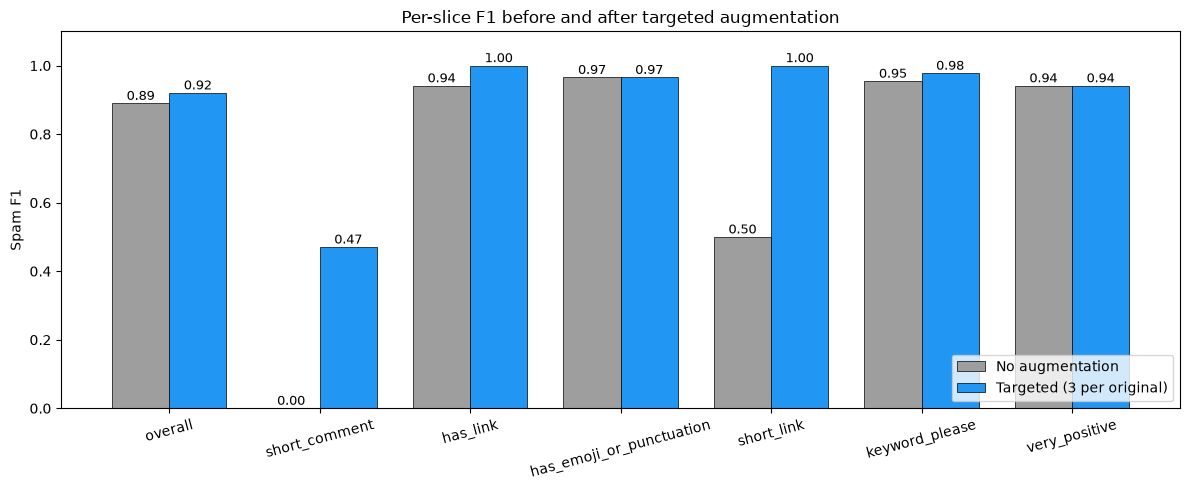

In [39]:
slice_names_plot = list(comparison.index)
x = np.arange(len(slice_names_plot))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 5))
b1 = ax.bar(x - width / 2, comparison[("f1", "before")], width, label="No augmentation", color="#9E9E9E", edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + width / 2, comparison[("f1", "after")], width, label=chosen_name, color="#2196F3", edgecolor="black", linewidth=0.5)
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(slice_names_plot, rotation=15)
ax.set_ylabel("Spam F1")
ax.set_ylim(0, 1.1)
ax.set_title("Per-slice F1 before and after targeted augmentation")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Analysis of the targeted augmentation

| Training set | Valid acc | Test acc | Short spam caught | Short ham flagged |
|---|---|---|---|---|
| No augmentation | 89.2% | 90.0% | 0 of 8 | 3 of 84 |
| Targeted, 3 per original (chosen on validation) | 90.8% | 92.4% | 4 of 8 | 5 of 84 |

**The fix worked on the slice it targeted.** Short-comment spam F1 went from 0.00 to 0.47. The model now catches both `adf.ly` links and two of the subscribe requests. The cost is 2 more short HAM comments flagged as spam.

**Other slices did not get worse.** Every slice kept or improved its F1. `has_link` went from 0.94 to 1.00 and `short_link` from 0.50 to 1.00, because `tf_swap_shortener` taught the model that shortener domains mean spam. Overall test accuracy rose from 90.0% to 92.4%.

**Targeting matters more than volume:**
- Generic synonym augmentation doubled the training set and changed nothing (89.6% test, still 0 short spam caught). Swapping "video" for "picture" does not create the kind of example the model is missing.
- The control with plain spam copies scored *worse* than no augmentation (85.8% valid, 89.6% test). Adding spam weight alone pushes the model toward SPAM everywhere without teaching it what short spam looks like. Its spam share (83%) is a bit higher than the targeted set's (76%) because every spam row gets copied, while my TFs skip comments they cannot transform.

**Limits:**
- 4 of the 8 short spam comments are still missed: `subscribe to my feed`, `subscribe  my`, `I subscribed it`, and `please visit my channel`. With only 8 short spam comments in the test set, each one moves the slice F1 a lot, so the slice numbers are noisy.
- Validation picked 3 per original (90.8%), while 2 per original happens to score higher on test (93.2%). I report the validation choice so the test set is not used for tuning.
- The augmented comments copy the weak labels, so any spam comment the LFs labeled wrong is copied 3 times. Only augmenting SPAM-labeled rows keeps this small, since the SPAM LFs were the most accurate on the dev set.

## Summary

In this lab, I built a spam classifier for YouTube comments using Snorkel's weak supervision approach. Instead of hand-labeling data, I wrote labeling functions (keyword, regex, factory-based, VADER sentiment, and a short-comment heuristic) that programmatically label training data. Then I used slicing to find where the classifier fails and targeted data augmentation to fix it.

### Key Findings:
- **Regex LFs improved coverage** over exact keyword matching (23.4% vs 21.6% for check-out phrases) by catching variations like "check me out" and "check it out".
- **VADER sentiment was inverted for this data.** Very positive comments are mostly spam and very negative ones are mostly ham. A labeled dev set caught this; flipping the rules turned two harmful LFs into two of the more accurate ones.
- **Label quality drives the final model.** Fixing the LF set raised majority-vote accuracy from 71.6% to 85.2% and the best classifier from 82.0% to 90.0% on the test set.
- **The LabelModel underperformed the MajorityVoter** (74.4% vs 85.2% on test), most likely because several of my SPAM LFs fire on the same comments. I chose between them on the validation set.
- **Logistic Regression is the best classifier at 90.0%**, followed by SVM (87.2%), Naive Bayes (86.8%), and Random Forest (85.6%).
- **Data slicing found a blind spot:** the model caught none of the 8 short spam comments in the test set, a side effect of the short-comment HAM rule.
- **Targeted augmentation fixed most of it.** Four TFs that turn long spam into short spam raised short-comment spam F1 from 0.00 to 0.47 and overall test accuracy from 90.0% to 92.4%, without hurting any other slice. Generic synonym augmentation and plain spam copies did not help.

### What I learned:
1. Writing good labeling functions is an iterative process: start with simple keywords, then improve with regex, sentiment, and heuristics.
2. Check LFs against a small labeled dev set. Coverage and conflicts cannot tell you that a rule points the wrong way.
3. More LFs is not always better. Duplicate or overly broad LFs (like matching "like" or labeling every 10-word comment as HAM) add noise.
4. The final classifier generalizes beyond the labeling functions and scores higher than the labels it was trained on.
5. Data slicing finds failure modes that overall accuracy hides.
6. Augmentation works when it targets a known gap. More data of the same kind (synonym swaps or copies) did nothing or made things worse.

### Differences from the original tutorial:
| Area | Original Tutorial | This Notebook |
|------|------------------|---------------|
| LF development | Fixed LF set | Iterative, five rounds, checked against a labeled dev set |
| Sentiment LFs | TextBlob | VADER (NLTK), direction flipped after dev set check |
| Featurization | CountVectorizer | TfidfVectorizer |
| Label source | LabelModel | MajorityVoter, chosen on the validation set |
| Classifiers | Logistic Regression only | 4 models: LogReg, Random Forest, SVM, Naive Bayes |
| Visualization | Basic histogram | Confusion matrix, bar charts, per-slice F1 |
| Data Slicing | Separate notebook (03) | Integrated, with 6 slices, used to find a blind spot |
| Data Augmentation | Separate notebook (02), generic TFs, LSTM never trained | 4 TFs targeted at the blind spot, compared with generic TFs and a spam-copies control, same classifier |
| Results (MV / LM / best classifier) | 83.6% / 86.4% / 93.2% | 85.2% / 74.4% / 90.0%, then 92.4% with targeted augmentation |